In [ ]:
import os
if not os.path.exists("/content/data/splits.csv"):
  from google.colab import drive
  drive.mount("/content/drive")
  !unzip -n -q "/content/drive/MyDrive/fruitnet.zip" -d /content/fruitnet
  !python "/content/fruitnet/archive (3)/01_limpieza_y_division.py" --origen "/content/fruitnet/archive (3)" --salida /content/data --solo-csv
else:
  print("Datos Listos")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Imágenes originales (buena + mala calidad): 18452
Copias aumentadas eliminadas: 4752
Duplicados exactos eliminados: 0 (0 hashes aparecían en más de una clase)
Imágenes con orden por número de secuencia: 793
Imágenes sin fecha ni secuencia (sesión propia): 0

Resumen por clase:
                   originales  limpias  sesiones  train   val  test
clase                                                             
Apple_Bad               1141     1141        35    800   171   170
Apple_Good              1149     1149       165    804   173   172
Banana_Bad              1087     1087        20    761   163   163
Banana_Good             1113     1113        24    779   166   168
Guava_Bad               1129     1129        30    790   169   170
Guava_Good              1152     1152        54    806   173   173
Lime_Bad                1085     1085        32    759  

In [ ]:
#!rm -rf /content/fruitnet /content/data
#!unzip -q "/content/drive/MyDrive/fruitnet.zip" -d /content/fruitnet

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image

In [ ]:
ORIGEN = "/content/fruitnet/archive (3)"
DATA = "/content/data"

In [ ]:
df = pd.read_csv(os.path.join(DATA, "splits.csv"))
resumen = pd.read_csv(os.path.join(DATA, "resumen_limpieza.csv"), index_col=0).drop("TOTAL")
CLASES = sorted(df["clase"].unique())
COLOR_CALIDAD = {"Good": "#2a9d8f", "Bad": "#e76f51"}

print(f"Imagenes: {len(df)} | Clases: {len(CLASES)} | Sesiones: {df['sesion'].nunique()}")
df.head()

Imagenes: 13700 | Clases: 12 | Sesiones: 588


,ruta,clase,fruta,calidad,archivo,timestamp,sesion,split
0,Bad Quality_Fruits/Apple_Bad/IMG_8131.JPG,Apple_Bad,Apple,Bad,IMG_8131.JPG,1.566240e+09,Apple_Bad_s00001,val
1,Bad Quality_Fruits/Apple_Bad/IMG_8132.JPG,Apple_Bad,Apple,Bad,IMG_8132.JPG,1.566240e+09,Apple_Bad_s00001,val
2,Bad Quality_Fruits/Apple_Bad/IMG_8133.JPG,Apple_Bad,Apple,Bad,IMG_8133.JPG,1.566240e+09,Apple_Bad_s00001,val
3,Bad Quality_Fruits/Apple_Bad/IMG_8134.JPG,Apple_Bad,Apple,Bad,IMG_8134.JPG,1.566240e+09,Apple_Bad_s00001,val
4,Bad Quality_Fruits/Apple_Bad/IMG_8135.JPG,Apple_Bad,Apple,Bad,IMG_8135.JPG,1.566240e+09,Apple_Bad_s00001,val


Desbalance (clase mayor / clase menor):
Antes: 5.47
Despues: 1.12


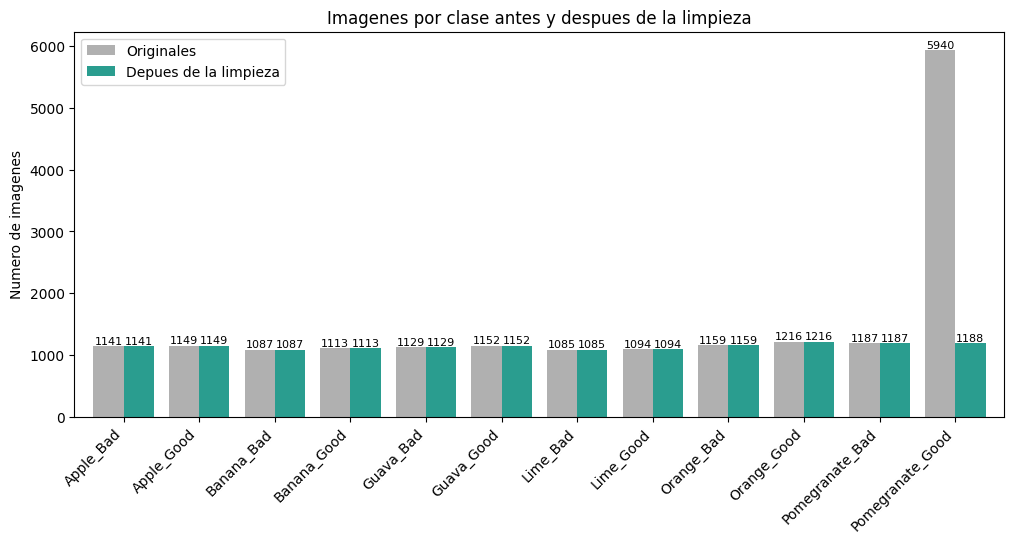

In [ ]:
ax = resumen[["originales", "limpias"]].plot(kind="bar", figsize=(12, 5), color=["#b0b0b0", "#2a9d8f"], width= 0.8)
ax.set_title("Imagenes por clase antes y despues de la limpieza")
ax.set_ylabel("Numero de imagenes"); ax.set_xlabel("")
ax.legend(["Originales", "Depues de la limpieza"])
for c in ax.containers:
  ax.bar_label(c, fontsize=8)
plt.xticks(rotation=45, ha="right");

print("Desbalance (clase mayor / clase menor):")
print(f"Antes: {resumen['originales'].max() / resumen['originales'].min():.2f}")
print(f"Despues: {resumen['limpias'].max() / resumen['limpias'].min():.2f}")

Porcentaje por conjunto en cada clase:
split             train   val  test
clase                              
Apple_Bad          70.1  15.0  14.9
Apple_Good         70.0  15.1  15.0
Banana_Bad         70.0  15.0  15.0
Banana_Good        70.0  14.9  15.1
Guava_Bad          70.0  15.0  15.1
Guava_Good         70.0  15.0  15.0
Lime_Bad           70.0  15.0  15.0
Lime_Good          70.2  14.9  14.9
Orange_Bad         70.0  15.1  14.9
Orange_Good        70.0  15.0  15.0
Pomegranate_Bad    70.0  15.0  15.0
Pomegranate_Good   70.0  15.0  15.0


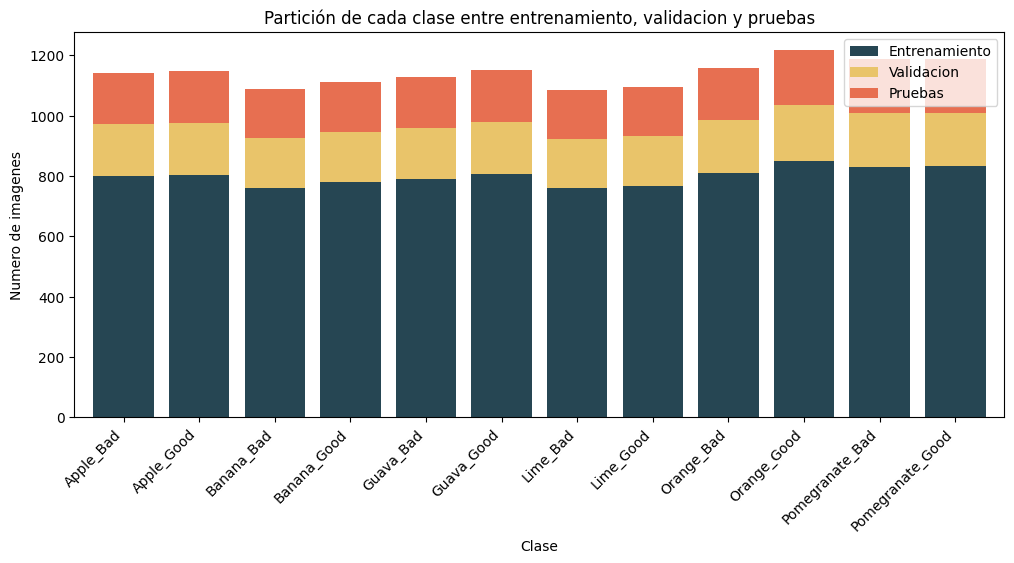

In [ ]:
tabla = pd.crosstab(df["clase"], df["split"])[["train", "val", "test"]]
ax = tabla.plot(kind="bar", stacked=True, figsize=(12,5), color=["#264653", "#e9c46a", "#e76f51"], width=0.8 )
ax.set_title("Partición de cada clase entre entrenamiento, validacion y pruebas")
ax.set_ylabel("Numero de imagenes"); ax.set_xlabel("Clase")
ax.legend(["Entrenamiento", "Validacion", "Pruebas"])
plt.xticks(rotation=45, ha="right")

print(f"Porcentaje por conjunto en cada clase:")
print((tabla.div(tabla.sum(axis=1), axis =0) *100).round(1))

In [ ]:
datos = []
for ruta in df["ruta"]:
  with Image.open(os.path.join(ORIGEN, ruta)) as im:
    datos.append((im.size[0], im.size[1], im.mode))
df[["ancho", "alto", "modo"]] = pd.DataFrame(datos, index=df.index)
df["resolucion"] = df["ancho"].astype(str) + "x" + df["alto"].astype(str)

print("Resoluciones encontradas:")
print(df["resolucion"].value_counts().to_string())
print("\nModos de color:")
print(df["modo"].value_counts().to_string())
pd.crosstab(df["clase"], df["resolucion"])

Resoluciones encontradas:
resolucion
256x256    8320
192x256    3968
256x192    1391
144x256      12
256x144       9

Modos de color:
modo
RGB    13700


resolucion,144x256,192x256,256x144,256x192,256x256
clase,,,,,
Apple_Bad,1,503,0,3,634
Apple_Good,0,116,0,33,1000
Banana_Bad,0,439,0,32,616
Banana_Good,0,218,0,36,859
Guava_Bad,0,408,0,119,602
Guava_Good,0,152,0,0,1000
Lime_Bad,11,613,9,71,381
Lime_Good,0,384,0,710,0
Orange_Bad,0,399,0,5,755


In [ ]:
df["cuadrada"] = df["ancho"] == df["alto"]
print((df["resolucion"].value_counts(normalize=True) * 100).round(1))
print("\n% de imágenes cuadradas por calidad:")
print((df.groupby("calidad")["cuadrada"].mean() * 100).round(1))

resolucion
256x256    60.7
192x256    29.0
256x192    10.2
144x256     0.1
256x144     0.1
Name: proportion, dtype: float64

% de imágenes cuadradas por calidad:
calidad
Bad     51.0
Good    70.2
Name: cuadrada, dtype: float64


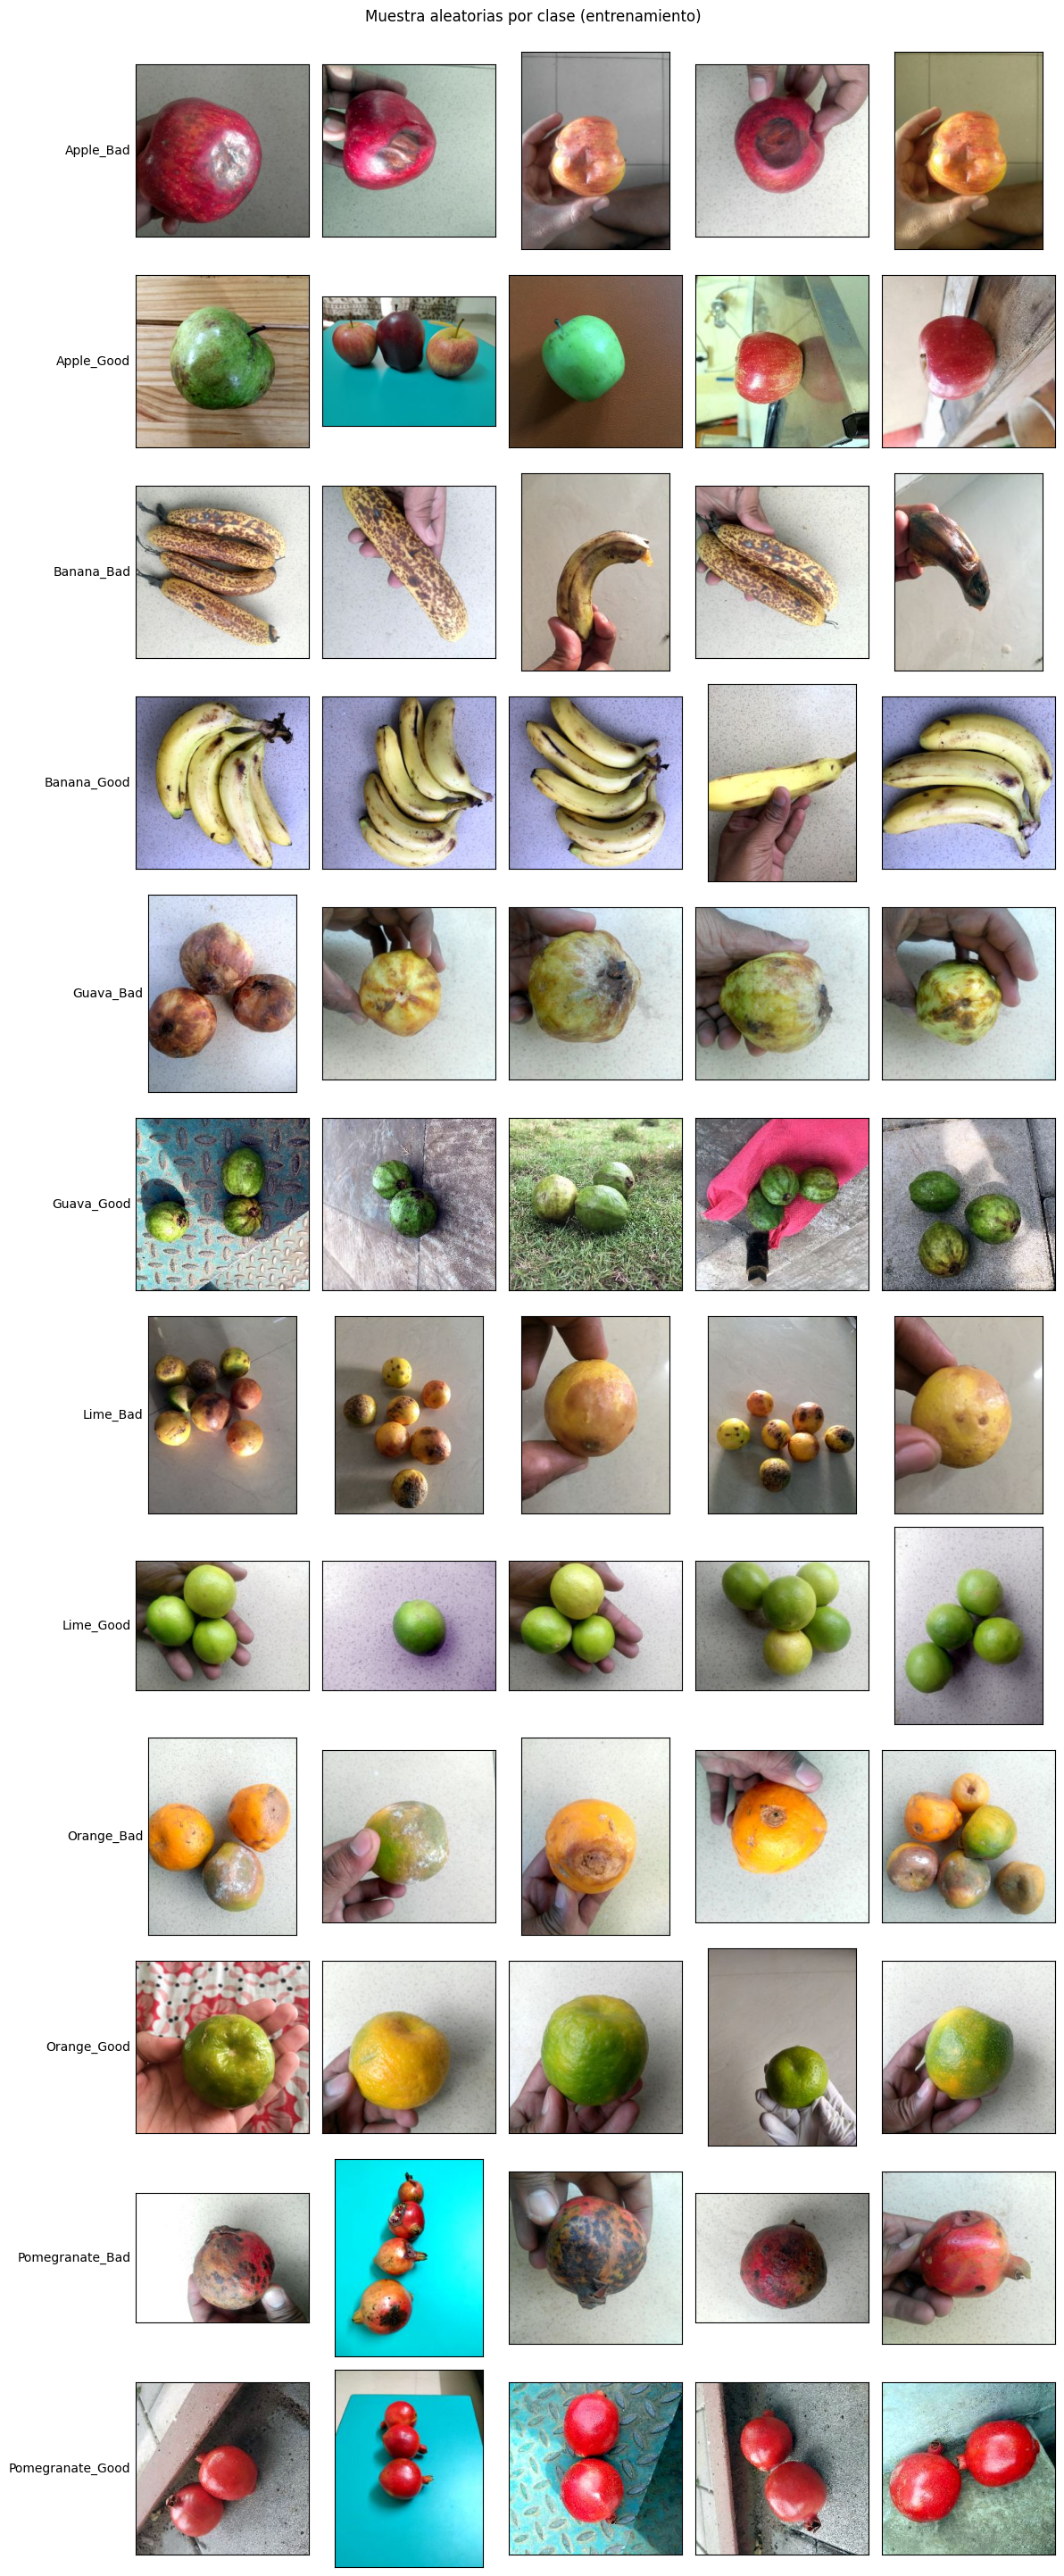

In [ ]:
N = 5
fig, axes = plt.subplots(len(CLASES), N, figsize=(2.4 * N, 2.4 * len(CLASES)))
for i, clase in enumerate(CLASES):
  muestras = df[(df["clase"] == clase) & (df["split"] == "train")].sample(N, random_state =42)
  for j, ruta in enumerate(muestras["ruta"]):
    axes[i, j].imshow(Image.open(os.path.join(ORIGEN, ruta)).convert("RGB"))
    axes[i, j].set_xticks([]); axes [i,j].set_yticks([])
  axes[i,0].set_ylabel(clase, fontsize=10, rotation=0, ha="right", va="center")
plt.suptitle("Muestra aleatorias por clase (entrenamiento)", y=1.0)
plt.tight_layout(); plt.show()


count    588.0
mean      23.3
std       38.5
min        1.0
25%        4.0
50%       10.0
75%       27.0
max      472.0

Sesiones por clase:
clase
Apple_Bad            35
Apple_Good          165
Banana_Bad           20
Banana_Good          24
Guava_Bad            30
Guava_Good           54
Lime_Bad             32
Lime_Good            22
Orange_Bad           26
Orange_Good          60
Pomegranate_Bad      38
Pomegranate_Good     82


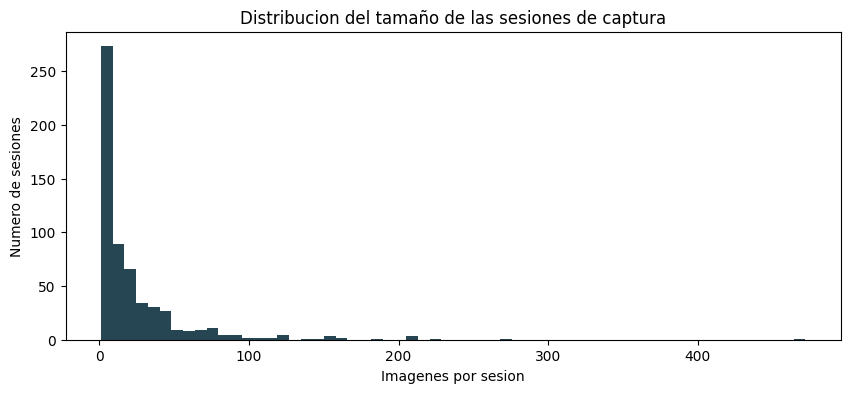

In [ ]:
ses = df.groupby("sesion").size()
print(ses.describe().round(1).to_string())

plt.figure(figsize=(10,4))
plt.hist(ses, bins=60, color="#264653")
plt.title("Distribucion del tamaño de las sesiones de captura")
plt.xlabel("Imagenes por sesion"); plt.ylabel("Numero de sesiones")

print("\nSesiones por clase:")
print(df.groupby("clase")["sesion"].nunique().to_string())

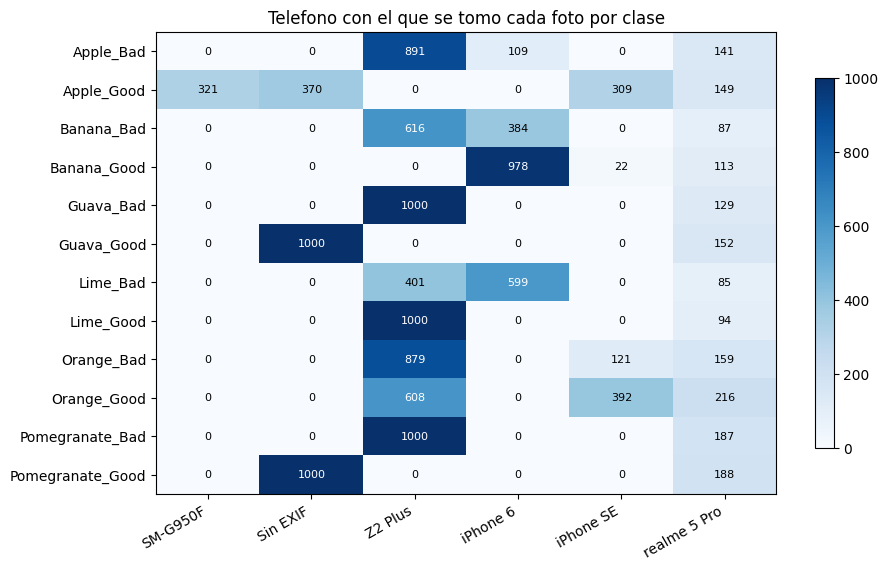

In [ ]:
def camara(ruta):
  try:
    return Image.open(os.path.join(ORIGEN, ruta)).getexif().get(272) or "Sin EXIF"
  except Exception:
    return "Error"
df["camara"] = [camara(r) for r in df["ruta"]]
cam = pd.crosstab(df["clase"], df["camara"])

fig, ax = plt.subplots(figsize=(10,6))
im = ax.imshow(cam.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(cam.shape[1])); ax.set_xticklabels(cam.columns, rotation=30, ha="right")
ax.set_yticks(range(cam.shape[0])); ax.set_yticklabels(cam.index)
for i in range(cam.shape[0]):
  for j in range(cam.shape[1]):
    v = cam.values[i, j]
    ax.text(j,i, v, ha="center", va="center", fontsize= 8, color = "white" if v > cam.values.max() /2 else "black")
ax.set_title("Telefono con el que se tomo cada foto por clase")
plt.colorbar(im, ax=ax, shrink=0.8);

periodo,2019,2020,Sin fecha
clase,,,
Apple_Bad,1000,141,0
Apple_Good,1000,149,0
Banana_Bad,1000,87,0
Banana_Good,1000,113,0
Guava_Bad,1000,129,0
Guava_Good,207,152,793
Lime_Bad,1000,85,0
Lime_Good,1000,94,0
Orange_Bad,1000,159,0


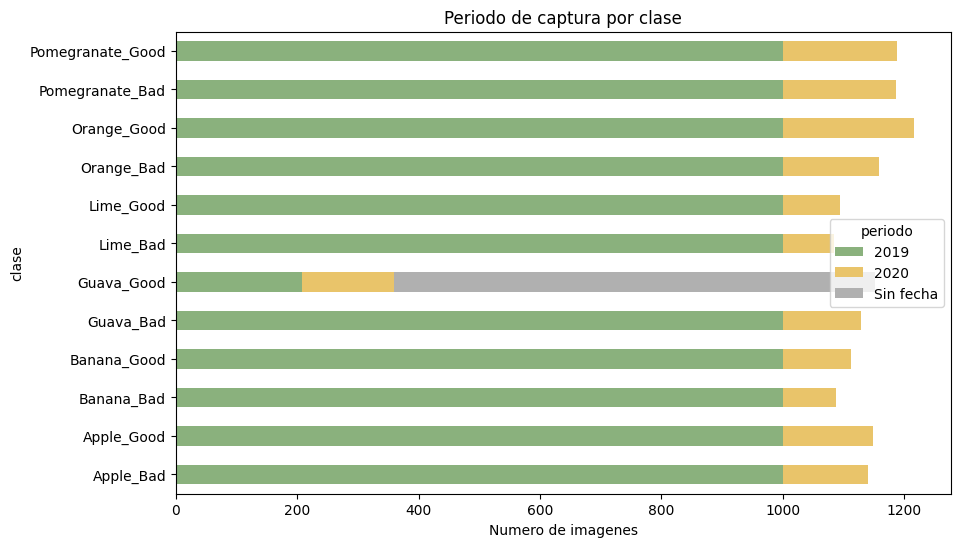

In [ ]:
df["periodo"] = "Sin fecha"
con_fecha = df["timestamp"] < 1e12
df.loc[con_fecha, "periodo"] = pd.to_datetime(df.loc[con_fecha, "timestamp"], unit="s").dt.year.astype(str)

per = pd.crosstab(df["clase"], df["periodo"])
ax = per.plot(kind="barh", stacked=True, figsize=(10,6), color =["#8ab17d", "#e9c46a", "#b0b0b0"])
ax.set_title("Periodo de captura por clase"); ax.set_xlabel("Numero de imagenes")
per

                  borde_verde  borde_claro
clase                                     
Apple_Bad                 2.0         48.6
Apple_Good                5.3         22.7
Banana_Bad                2.1         63.4
Banana_Good               2.8         44.1
Guava_Bad                 0.9         62.5
Guava_Good                9.4         25.0
Lime_Bad                  0.2         37.2
Lime_Good                 2.5         58.5
Orange_Bad                1.1         63.3
Orange_Good               4.2         36.9
Pomegranate_Bad           3.5         54.5
Pomegranate_Good         23.4         19.1

 Promedio por calidad:
         borde_verde  borde_claro
calidad                          
Bad              1.6         54.9
Good             7.9         34.4


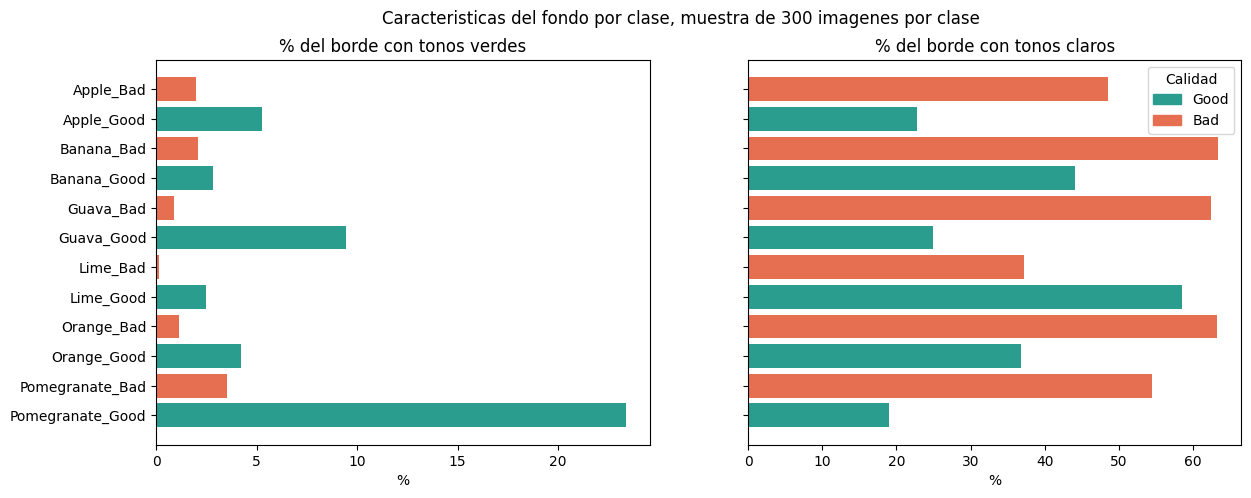

In [ ]:
def analizar_borde(ruta, margen=0.12, lado=64):
  im= np.asarray(Image.open(os.path.join(ORIGEN, ruta)).convert("RGB").resize((lado, lado)), dtype=np.float32)
  k = int(lado * margen)
  borde = np.concatenate([im[:k].reshape(-1,3), im[-k:].reshape(-1,3), im[:, :k].reshape(-1,3), im[:, -k:].reshape(-1,3)])
  r,g,b = borde[:, 0], borde[:, 1], borde[:,2]
  verde = np.mean((g> r +10) & (g>b +10))
  claro = np.mean(borde.min(axis=1) >170)
  return verde, claro

muestra = df.groupby("clase").sample(n=300, random_state=42).copy()
muestra[["borde_verde", "borde_claro"]] = [analizar_borde(r) for r in muestra["ruta"]]
fondo = muestra.groupby("clase")[["borde_verde", "borde_claro"]].mean() * 100

fig, axes = plt.subplots(1,2, figsize=(14,5), sharey=True)
colores = [COLOR_CALIDAD[c.split("_")[1]] for c in fondo.index]
for ax, col, titulo in zip(axes, ["borde_verde", "borde_claro"], ["% del borde con tonos verdes", "% del borde con tonos claros"]):
  ax.barh(fondo.index, fondo[col], color=colores)
  ax.set_title(titulo); ax.set_xlabel("%")
axes[0].invert_yaxis()
axes[1].legend(handles=[Patch(color=v, label=k) for k, v in COLOR_CALIDAD.items()], title="Calidad")
plt.suptitle("Caracteristicas del fondo por clase, muestra de 300 imagenes por clase")

print(fondo.round(1).to_string())
print("\n Promedio por calidad:")
print((muestra.groupby("calidad")[["borde_verde", "borde_claro"]].mean()*100).round(1).to_string())